# Fronda Italia · Ricerca sul modello di previsione

**16 ottobre 2026. Quaderno di verifica degli input, senza modello italiano addestrato.**

Il prototipo prepara variabili meteorologiche con ritardi e può imparare la probabilità di
almeno un ritrovamento per uscita da visite standardizzate. Le componenti biologiche
di presenza, fruttificazione e rilevamento richiedono dati diversi: non sono tre
punteggi da moltiplicare. La ricerca e le fonti sono in `ricerca.md` e `letteratura.md`.
Gli accessi a testi integrali e supplementi sono in `accesso-studi.md`.

Questo quaderno usa una risposta **reale** Open-Meteo su un punto di Rieti, acquisita
il 16 ottobre (ora italiana). Verifica dati mancanti, bilancio climatico e rispetto
del calendario. I dati sono uscite di modelli meteo; non sono misure del sottobosco.
Nessun ritrovamento simulato e nessuna accuratezza biologica sono presentati.

**Risultato:** le finestre brevi sono calcolabili; la finestra più remota contiene
valori mancanti. Ospiti, chioma, pH e umidità del suolo non sono stati acquisiti.
Le probabilità pubbliche rimangono indisponibili. P − ET₀ è una covariata climatica,
non una misura dell'acqua effettivamente disponibile ai funghi.

## 1. Caricare fonte e codice

Il quaderno si esegue offline dalla copia del repository. Installazione:
`python -m pip install -r tools/fronda_model/requirements.txt`.
Le versioni del software vengono registrate sotto; l'accesso ai dati privati non serve.

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib.metadata, os, tempfile
os.environ.setdefault('MPLCONFIGDIR', tempfile.mkdtemp(prefix='fronda-matplotlib-'))
os.environ.setdefault('XDG_CACHE_HOME', tempfile.mkdtemp(prefix='fronda-cache-'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

cwd = Path.cwd().resolve()
repo = next(p for p in [cwd, *cwd.parents] if (p / 'tools/fronda_model/features.py').exists())
sys.path.insert(0, str(repo))
from tools.fronda_model.features import build_features, FEATURE_NAMES
base = repo / 'tools/fronda_model'
source = json.loads((base / 'data/weather-rieti-2026-10-16.json').read_text())
context = json.loads((base / 'data/context-rieti.json').read_text())
target_date = '2026-10-16'
snapshot_hash = hashlib.sha256(json.dumps(source['rows'], sort_keys=True, separators=(',', ':')).encode()).hexdigest()
assert snapshot_hash == source['metadata']['sha256_rows']
display(pd.Series({key: source['metadata'][key] for key in ['provider', 'fetched_at', 'weather_provenance', 'licence', 'request_url']}, name='Fonte'))
display(pd.Series({name: importlib.metadata.version(name) for name in ['numpy','pandas','matplotlib','scikit-learn']}, name='Versione'))


provider                                                     Open-Meteo
fetched_at                             2026-10-15T23:38:26.838905+00:00
weather_provenance                                 current_api_snapshot
licence                                                       CC BY 4.0
request_url           https://api.open-meteo.com/v1/forecast?latitud...
Name: Fonte, dtype: object

numpy            2.3.5
pandas           2.2.3
matplotlib      3.10.8
scikit-learn     1.8.0
Name: Versione, dtype: object

## 2. Distinguere lacune e zero

Gli 82 giorni della risposta includono passato e futuro rispetto al bersaglio.
La costruzione delle variabili considera soltanto i 60 giorni precedenti.
La selezione per data non dimostra che un dato fosse disponibile al momento di
una previsione storica: manca l'emissione della corsa meteorologica.

In [2]:
weather = pd.DataFrame(source['rows'])
weather['date'] = pd.to_datetime(weather['date'])
display(pd.DataFrame({'Valori mancanti': weather.drop(columns='date').isna().sum(), 'Zeri presenti': weather.drop(columns='date').eq(0).sum()}))
features = build_features(source['rows'], target_date, context, issued_at=source['metadata']['fetched_at'])
display(pd.Series({'Variabili candidate': len(FEATURE_NAMES), 'Calcolabili': len(features['quality']['complete_features']), 'Mancanti': len(features['quality']['missing_features']), 'Disponibilità storica': features['quality']['availability_audit_status'], 'Probabilità pubblica': None}, name='Verifica input'))
assert features['quality']['availability_audit_status'] == 'unknown'
assert all(day < target_date for day in features['provenance']['used_dates'])
assert features['values']['host_fraction'] is None


,Valori mancanti,Zeri presenti
precipitation_mm,16,45
temperature_mean_c,16,0
temperature_min_c,15,0
temperature_max_c,15,0
et0_mm,16,0


Variabili candidate           31
Calcolabili                   19
Mancanti                      12
Disponibilità storica    unknown
Probabilità pubblica        None
Name: Verifica input, dtype: object

## 3. Leggere il meteo antecedente

Pioggia ed ET₀ hanno la stessa unità, ma processi diversi. ET₀ rappresenta la
domanda evaporativa di riferimento di un prato ben irrigato, non l'evaporazione
misurata nel bosco. Le fasce grigie indicano dati mancanti, non giornate asciutte.
Fonte e unità: [Open-Meteo](https://open-meteo.com/en/docs).

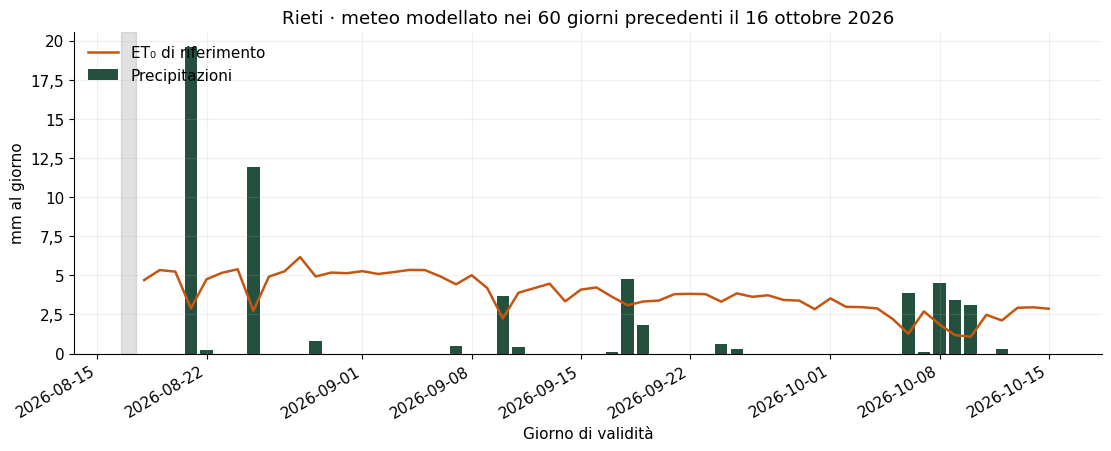

In [3]:
plt.rcParams.update({'font.size': 11, 'figure.figsize': (11, 4.4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
window = weather[(weather['date'] >= pd.Timestamp(target_date)-pd.Timedelta(days=60)) & (weather['date'] < pd.Timestamp(target_date))].copy()
fig, ax = plt.subplots(layout='constrained')
ax.bar(window['date'], window['precipitation_mm'], color='#24513D', label='Precipitazioni')
ax.plot(window['date'], window['et0_mm'], color='#C55612', linewidth=1.8, label='ET₀ di riferimento')
for day in window.loc[window['precipitation_mm'].isna(), 'date']:
    ax.axvspan(day-pd.Timedelta(hours=12), day+pd.Timedelta(hours=12), color='#777777', alpha=.22)
ax.set(title='Rieti · meteo modellato nei 60 giorni precedenti il 16 ottobre 2026', ylabel='mm al giorno', xlabel='Giorno di validità')
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'.replace('.', ',')))
ax.legend(frameon=False, loc='upper left')
fig.autofmt_xdate()
plt.show()


## 4. Verificare le finestre di ritardo

Le quattro finestre non si sovrappongono e hanno rispettivamente 7, 7, 16 e 30
giorni. Sono ipotesi ingegneristiche da confrontare nei soli dati di training,
non tempi universali di nascita. Un solo valore mancante rende indisponibile
l'aggregato della relativa variabile.

,Finestra (giorni prima),Durata (giorni),Pioggia (mm),ET₀ (mm),P − ET₀ (mm)
0,0–7,7,"6,80","15,62","-8,82"
1,7–14,7,"8,50","16,89","-8,39"
2,14–30,16,"7,60","56,81","-49,21"
3,30–60,30,—,—,—


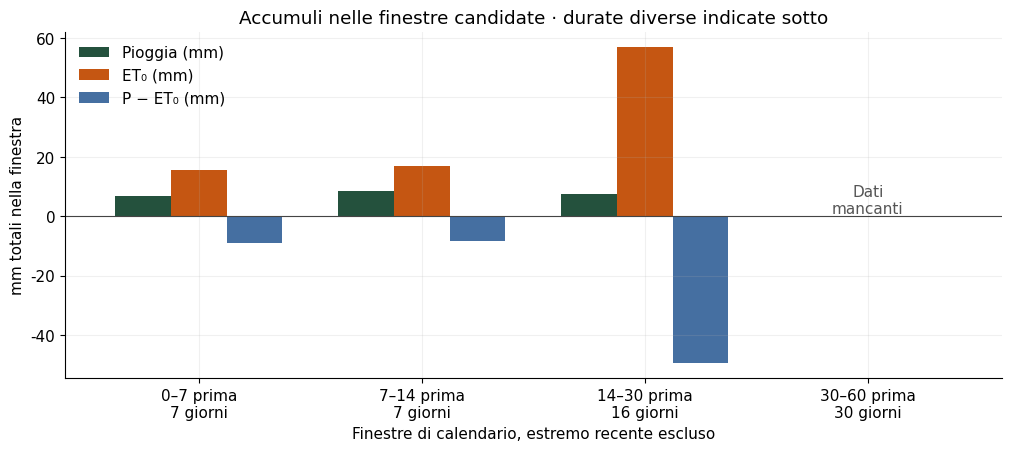

In [4]:
lag_rows = []
for lower, upper in [(0,7),(7,14),(14,30),(30,60)]:
    suffix = f'lag_{lower}_{upper}d'
    lag_rows.append({'Finestra (giorni prima)': f'{lower}–{upper}', 'Durata (giorni)': upper-lower, 'Pioggia (mm)': features['values'][f'precipitation_sum_mm_{suffix}'], 'ET₀ (mm)': features['values'][f'et0_sum_mm_{suffix}'], 'P − ET₀ (mm)': features['values'][f'climatic_balance_mm_{suffix}']})
lags = pd.DataFrame(lag_rows)
display(lags.style.format(precision=2, decimal=',', na_rep='—'))
fig, ax = plt.subplots(figsize=(10,4.4), layout='constrained')
x = np.arange(len(lags)); width=.25
for offset, name, color in [(-width,'Pioggia (mm)','#24513D'), (0,'ET₀ (mm)','#C55612'), (width,'P − ET₀ (mm)','#456FA1')]:
    ax.bar(x+offset, lags[name], width, label=name, color=color)
for i, row in lags.iterrows():
    if pd.isna(row['P − ET₀ (mm)']): ax.text(i, 0, 'Dati\nmancanti', ha='center', va='bottom', color='#555555')
ax.axhline(0, color='#444444', linewidth=.8)
ax.set_xlim(-.6, len(lags)-.4)
ax.set_xticks(x, [f'{row["Finestra (giorni prima)"]} prima\n{row["Durata (giorni)"]} giorni' for _,row in lags.iterrows()])
ax.set(title='Accumuli nelle finestre candidate · durate diverse indicate sotto', ylabel='mm totali nella finestra', xlabel='Finestre di calendario, estremo recente escluso')
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'.replace('.', ',')))
ax.legend(frameon=False)
plt.show()


## 5. Controllare il limite dell'evidenza

Il prototipo `learning.py` addestra una regressione logistica regolarizzata e
calibra su un insieme separato. Il test richiede tempi e blocchi geografici
distinti; sforzo e protocollo fanno parte del target. I test software usano
fixture dichiarate, non dati micologici reali.

Non è stato addestrato un modello italiano: mancano visite di ricerca con
non-rilevazioni, sforzo, identificazioni controllate e consenso specifico.
I fattori nascosti di distribuzione, fruttificazione e rilevamento non sono
separatamente identificati dal prototipo. Non si stima crescita in mm/giorno
o biomassa. Il ritorno pubblico resta `null` anche per artefatti addestrati.

L'architettura nazionale, il confronto con Fronda attuale, le fonti e i criteri
di promozione sono in `ricerca.md`, `dati-validazione.md` e `audit-fronda.md`.
I risultati meteorologici sopra verificano l'esecuzione della pipeline, non
un aumento dell'accuratezza dei ritrovamenti.